# Text preprocessing as a measurable modeling decision

This experiment studies how tokenization and normalization change corpus statistics. The main output is a Zipf fit with a bootstrap interval, followed by an audit of edge cases that matter in downstream tasks such as sentiment analysis and biomedical entity recognition.

The central rule is task dependence: case folding and punctuation removal can stabilize frequency estimates, while the same operations can destroy signals such as negation, gene symbols and entity boundaries.

In [2]:
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

from nlp_portfolio.preprocessing import simple_tokens, zipf_slope

examples = ["don't", "IL-6", "BRCA1", "New York", "patient's", "SARS-CoV-2"]
pd.DataFrame({"text": examples, "regex_tokens": [simple_tokens(x) for x in examples]})

,text,regex_tokens
0,don't,[don't]
1,IL-6,"[il, 6]"
2,BRCA1,[brca1]
3,New York,"[new, york]"
4,patient's,[patient's]
5,SARS-CoV-2,"[sars, cov, 2]"


## Corpus and Zipf fit

Zipf's law predicts an approximately linear relationship between log rank and log frequency. Filtering hapax legomena reduces instability in the tail. The fitted slope describes this corpus and preprocessing pipeline; it is not a universal constant.

tokens=1,585,421; vocabulary=39,800; slope=-1.376


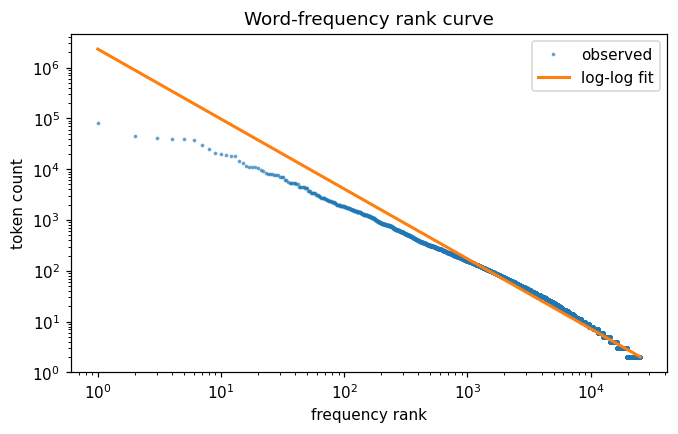

In [4]:
url = "https://www.math.unipd.it/~dasan/christie.txt"
response = requests.get(url, timeout=30)
response.raise_for_status()
tokens = simple_tokens(response.text)
slope, intercept, ranks, frequencies = zipf_slope(tokens, min_count=2)
print(f"tokens={len(tokens):,}; vocabulary={len(set(tokens)):,}; slope={slope:.3f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.loglog(ranks, frequencies, ".", ms=3, alpha=0.55, label="observed")
ax.loglog(ranks, np.exp(intercept) * ranks**slope, lw=2, label="log-log fit")
ax.set(xlabel="frequency rank", ylabel="token count", title="Word-frequency rank curve")
ax.legend()
plt.show()

In [5]:
rng = np.random.default_rng(42)
bootstrap_slopes = []
for _ in range(300):
    sample = rng.choice(tokens, size=len(tokens), replace=True)
    bootstrap_slopes.append(zipf_slope(sample, min_count=2)[0])
interval = np.quantile(bootstrap_slopes, [0.025, 0.975])
print(f"bootstrap 95% interval: [{interval[0]:.3f}, {interval[1]:.3f}]")

bootstrap 95% interval: [-1.366, -1.361]


The interval measures sampling variation conditional on the selected corpus and preprocessing. It does not capture author, genre or language variation.

## Vocabulary growth

Heaps' law complements Zipf statistics by measuring how quickly new word types appear. A curve that keeps growing indicates that vocabulary coverage remains incomplete.

In this run the original slope (-1.376) falls outside the bootstrap percentile interval (-1.366 to -1.361). Token resampling can change which rare words pass `min_count=2`; the result is sensitive to this filtering. It should not be interpreted as uncertainty across books or authors.

Heaps exponent=0.654


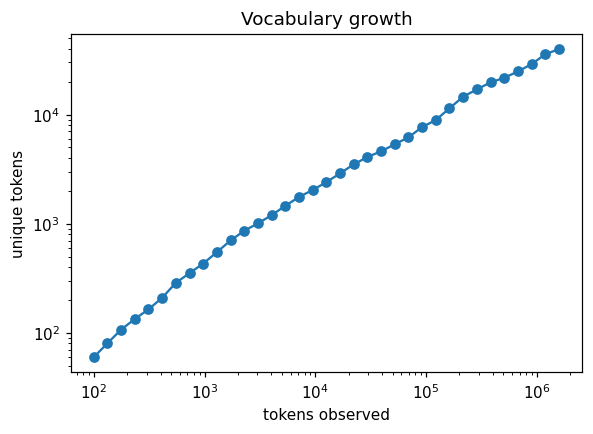

In [7]:
checkpoints = np.unique(np.geomspace(100, len(tokens), 35).astype(int))
vocabulary_size = [len(set(tokens[:n])) for n in checkpoints]
coefficient, exponent = np.polyfit(np.log(checkpoints), np.log(vocabulary_size), 1)[::-1]
print(f"Heaps exponent={exponent:.3f}")

plt.figure(figsize=(6, 4))
plt.loglog(checkpoints, vocabulary_size, "o-")
plt.xlabel("tokens observed")
plt.ylabel("unique tokens")
plt.title("Vocabulary growth")
plt.show()

## Stemming, lemmatization and information loss

Stemming applies surface rules, while lemmatization uses vocabulary and part-of-speech information. WordNet defaults to noun interpretation, so the POS tag must be supplied when verbs matter.

In [9]:
import nltk
from nltk.stem import SnowballStemmer, WordNetLemmatizer

try:
    nltk.data.find("corpora/wordnet.zip")
except LookupError:
    try:
        nltk.data.find("corpora/wordnet")
    except LookupError:
        if not nltk.download("wordnet", quiet=True):
            raise RuntimeError("Install the NLTK wordnet corpus before running this notebook.")
stemmer = SnowballStemmer("english")
lemmatizer = WordNetLemmatizer()
words = ["studies", "running", "better", "scientists"]
pd.DataFrame({
    "word": words,
    "stem": [stemmer.stem(x) for x in words],
    "noun_lemma": [lemmatizer.lemmatize(x) for x in words],
    "verb_lemma": [lemmatizer.lemmatize(x, pos="v") for x in words],
})

,word,stem,noun_lemma,verb_lemma
0,studies,studi,study,study
1,running,run,running,run
2,better,better,better,better
3,scientists,scientist,scientist,scientists


### Reproducibility notes

The source URL, case-folding rule and `min_count` threshold are explicit. For NER, retain the original text and offsets. For sentiment, verify that negation survives preprocessing. For gene and protein names, use a domain tokenizer because hyphens, digits and capitalization can encode identity.